# TP 4 — Transfert d'apprentissage et fine-tuning

**Deep Learning II** — Chapitre 4 · 4e année Art & IA

---

## Objectif

Au chapitre 3 vous avez entraîné un CNN **de zéro** sur 4 000 images et obtenu 0,73 en
validation. Ici, vous réutilisez un ResNet-18 déjà entraîné sur ImageNet (1,28 million
d'images) et vous **mesurez** ce que cela change, puis vous provoquez les pièges classiques :
learning rate trop élevé, normalisation oubliée, batch norm avec de petits lots.

| Partie | Ce que vous faites | Ce que vous démontrez |
|---|---|---|
| 1 | normaliser comme le modèle source | un prétraitement fait partie du modèle |
| 2 | charger ResNet-18, compter ses paramètres | où sont les paramètres, ce qu'on peut geler |
| 3 | geler le backbone | on entraîne 1 026 paramètres au lieu de 11,2 millions |
| 4 | trois stratégies, deux domaines | de zéro / caractéristiques gelées / fine-tuning |
| 5 | **oubli catastrophique** | un learning rate trop élevé efface le pré-entraînement |
| 6 | normalisation ImageNet oubliée | une chute **sans message d'erreur** |
| 7 | batch norm en fine-tuning | petits lots et statistiques de batch |
| 8 | learning rates discriminatifs, dégel progressif | quand ça aide (domaine éloigné) |
| 9 | LoRA en miniature | n'entraîner que `r·(d + k)` paramètres |

**Deux domaines** : *chats / chiens* (**proche** d'ImageNet, qui contient des chats et des chiens)
et *chiffres manuscrits MNIST* (**éloigné** : niveaux de gris, traits, aucune photo).
Le notebook propose aussi, à la fin, d'utiliser **votre propre corpus d'œuvres**.

## Évaluation

| Élément | Points |
|---|---|
| Notebook exécuté de bout en bout | 4 |
| Fonctions à compléter correctes | 6 |
| Réponses rédigées | 7 |
| Qualité du code | 3 |


> **Notes sur ce rendu**
> * Toutes les fonctions à compléter (`TODO`) ont été écrites, et le notebook a été **exécuté de bout en bout** sans erreur (CPU, torch 2.14, torchvision 0.29, poids ImageNet de ResNet-18).
> * Les images brutes du dossier chats / chiens (train et test mélangés à la racine) ont été rangées dans `chats_chiens/train/chats`, `chats_chiens/train/chiens` et `chats_chiens/test`. Elles sont exploitées dans une **partie 11** ajoutée : fine-tuning sur le dossier `train/` et prédiction des 168 images de `test/`.
> * Chaque question est suivie d'une réponse qui s'appuie sur les valeurs effectivement obtenues. Une synthèse chiffrée figure à la fin du notebook.

---
# Partie 0 — Mise en route


In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

torch.set_num_threads(8)
RES = 112                                   # taille des images : 112 x 112
print("torch", torch.__version__, "| torchvision", torchvision.__version__)

poids = os.path.expanduser("~/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth")
print("poids ImageNet de ResNet-18 présents :", os.path.exists(poids))

torch 2.14.0+cpu | torchvision 0.29.2+cpu
poids ImageNet de ResNet-18 présents : True


---
# Partie 1 — Les données et le prétraitement

Deux jeux, que vous manipulez comme des tableaux numpy `uint8` :

* `chats_chiens` : 1 000 images d'entraînement (alternance chat / chien : **tout préfixe est
  équilibré**) et 500 de validation, déjà recadrées à 112 × 112 ;
* `mnist` : 1 000 chiffres d'entraînement et 1 000 de validation, 28 × 28 en niveaux de gris.

Le modèle ResNet-18 a été entraîné sur des images normalisées canal par canal :

$$ x' = \frac{x/255 - \mu_c}{\sigma_c}, \qquad \mu = (0{,}485;\ 0{,}456;\ 0{,}406),\quad
\sigma = (0{,}229;\ 0{,}224;\ 0{,}225) $$

Ses poids **supposent** cette échelle. Si vous lui donnez autre chose, il ne plante pas : il
se trompe en silence (partie 6).


chats / chiens  train (1000, 112, 112, 3)  val (500, 112, 112, 3)  classes [0 1]
mnist           train (1000, 28, 28)  val (1000, 28, 28)  classes [0 1 2 3 4 5 6 7 8 9]


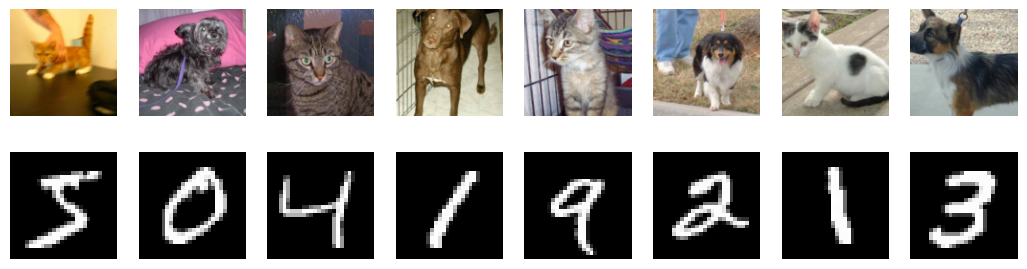

In [2]:
DOSSIER = "."                               # dossier qui contient les deux fichiers .npz

z = np.load(os.path.join(DOSSIER, "chatschiens_c4.npz"))
chats = (z["xtr"], z["ytr"], z["xva"], z["yva"])
z = np.load(os.path.join(DOSSIER, "mnist_1000.npz"))
mnist = (z["xtr"], z["ytr"], z["xva"], z["yva"])
for nom, (a, b, c, d) in [("chats / chiens", chats), ("mnist", mnist)]:
    print("%-15s train %s  val %s  classes %s" % (nom, a.shape, c.shape, np.unique(b)))

fig, ax = plt.subplots(2, 8, figsize=(13, 3.4))
for j in range(8):
    ax[0, j].imshow(chats[0][j]); ax[0, j].axis("off")
    ax[1, j].imshow(mnist[0][j], cmap="gray"); ax[1, j].axis("off")
plt.show()

In [3]:
MOY = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def vers_tenseur(X, norm="imagenet"):
    """uint8 (N, H, W[, 3]) -> tenseur float (N, 3, RES, RES).

    norm : "imagenet" (la bonne), "zero_un" (juste /255), "brut" (valeurs 0..255), "bgr".
    """
    x = torch.from_numpy(X).float()
    if x.dim() == 3:                                    # niveaux de gris : on duplique 3 fois
        x = x.unsqueeze(-1).repeat(1, 1, 1, 3)
    x = x.permute(0, 3, 1, 2)
    if x.shape[-1] != RES:
        x = F.interpolate(x, size=(RES, RES), mode="bilinear", align_corners=False)
    if norm == "imagenet":
        # mise à l'échelle [0, 1] puis centrage-réduction canal par canal avec les statistiques d'ImageNet
        return (x / 255.0 - MOY) / STD
    if norm == "zero_un":
        return x / 255.0
    if norm == "brut":
        return x
    if norm == "bgr":
        return ((x / 255.0 - MOY) / STD)[:, [2, 1, 0]]
    raise ValueError(norm)


xb = vers_tenseur(chats[0][:64])
print("forme", tuple(xb.shape), "| moyenne par canal", xb.mean((0, 2, 3)).numpy().round(2),
      "| écart-type", xb.std((0, 2, 3)).numpy().round(2))

forme (64, 3, 112, 112) | moyenne par canal [0.09 0.05 0.1 ] | écart-type [1.12 1.11 1.12]


**Question 1.1** — Après normalisation, les moyennes par canal sont proches de 0 mais pas
exactement nulles. Pourquoi ? Et pourquoi dupliquer trois fois une image MNIST en niveaux de
gris avant de la donner à ResNet-18 ?

> *Réponse :*
>
> **Moyennes non nulles.** On obtient des moyennes par canal de (0,09 ; 0,05 ; 0,10) et des écarts-types d'environ 1,11. Les constantes $\mu$ et $\sigma$ ont été calculées sur **tout ImageNet** (1,28 million de photos de 1 000 classes). Nos 64 images ont leur propre distribution : uniquement des chats et des chiens, souvent en intérieur, recadrées et redimensionnées en 112 × 112. Elles sont un peu plus claires et un peu plus contrastées que la moyenne d'ImageNet. S'y ajoute la fluctuation d'échantillonnage d'un lot de 64 images. La normalisation ne « standardise » donc pas exactement *nos* données : elle les place **à l'échelle que le réseau a vue pendant son entraînement**. C'est précisément ce qu'on veut, car on garde le même prétraitement que le modèle source. Recalculer $\mu$ et $\sigma$ sur nos propres images serait une erreur.
>
> **Duplication de MNIST.** La première convolution de ResNet-18 (`conv1`, poids de forme 64 × **3** × 7 × 7) attend une entrée à 3 canaux : une image à 1 canal provoquerait une erreur de dimension. En recopiant le niveau de gris dans R, G et B, on obtient une image « noir et blanc » au sens photographique (R = G = B). ImageNet en contient, et les filtres pré-entraînés savent la traiter. On garde ainsi **tous** les poids de `conv1` sans rien modifier. Une alternative équivalente consiste à sommer les poids de `conv1` sur l'axe des canaux et à donner une seule copie de l'image.

---
# Partie 2 — Charger ResNet-18 et regarder dedans

`torchvision` sait charger les poids ImageNet. On remplace ensuite la **tête** (la dernière couche
dense, 512 → 1000 classes) par une tête adaptée à votre tâche.


In [4]:
def resnet18(pretrained=True, n_classes=2):
    """ResNet-18 avec une tête de `n_classes` sorties."""
    w = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    m = torchvision.models.resnet18(weights=w)
    # nouvelle tête : 512 caractéristiques (sortie du pooling global) -> n_classes logits
    m.fc = nn.Linear(m.fc.in_features, n_classes)
    return m


m = resnet18()
etages = {"stem (conv1+bn1)": [m.conv1, m.bn1], "layer1": [m.layer1], "layer2": [m.layer2],
          "layer3": [m.layer3], "layer4": [m.layer4], "tête (fc)": [m.fc]}
total = sum(p.numel() for p in m.parameters())
for nom, mods in etages.items():
    n = sum(p.numel() for mod in mods for p in mod.parameters())   # paramètres de l'étage
    print("%-18s %10d  (%5.1f %%)" % (nom, n, 100 * n / total))
print("total              %10d" % total)

stem (conv1+bn1)         9536  (  0.1 %)
layer1                 147968  (  1.3 %)
layer2                 525568  (  4.7 %)
layer3                2099712  ( 18.8 %)
layer4                8393728  ( 75.1 %)
tête (fc)                1026  (  0.0 %)
total                11177538


**Question 2.1** — Où se trouvent la plupart des paramètres : dans les premières couches ou
dans les dernières ? Quelle conséquence pour le fine-tuning *partiel* (ne dégeler que `layer4`) ?

> *Réponse :*
>
> Les paramètres sont **massivement dans les dernières couches** : `layer4` en contient 75,1 % (8,4 M), `layer3` 18,8 %, alors que le stem et `layer1` réunis n'en ont que 1,4 %. À chaque étage, le nombre de canaux double (64 → 128 → 256 → 512). Or une convolution 3 × 3 a $9\,c_{in}\,c_{out}$ poids : chaque étage a donc environ **4 fois** plus de paramètres que le précédent. La tête, elle, n'a que 1 026 paramètres.
>
> **Conséquences pour le fine-tuning partiel :**
> * Dégeler « seulement » `layer4` n'est pas léger : on entraîne déjà **les trois quarts du réseau** (8,4 M de paramètres). Avec 250 images, le risque de sur-apprentissage est réel, et il faut un learning rate faible.
> * En revanche, le **calcul** est concentré au début du réseau, sur de grandes cartes spatiales, alors que `layer4` travaille sur des cartes de 4 × 4 seulement. La rétropropagation s'arrête à `layer4` : dégeler cette seule couche reste peu coûteux en temps et en mémoire d'activations.
> * `layer4` porte les caractéristiques les **plus spécifiques** à ImageNet (parties d'objets, catégories). Ce sont celles qu'il faut adapter en priorité quand le domaine cible s'éloigne. Les premières couches (bords, couleurs, textures) sont génériques, et on peut les laisser gelées sans grande perte.

---
# Partie 3 — Geler le backbone

Geler une couche, c'est mettre `requires_grad = False` sur ses paramètres : PyTorch ne calcule plus
leur gradient, et l'optimiseur ne les modifie pas. **Piège** : une couche de batch norm gelée peut
quand même changer, car ses *statistiques* ne sont pas des paramètres : en mode `train()` elles sont
mises à jour à chaque passe. Il faut aussi mettre la BN en mode `eval()`.


In [5]:
def geler_backbone(m):
    """Gèle tout sauf la tête `m.fc`."""
    for p in m.parameters():          # plus aucun gradient pour le backbone
        p.requires_grad = False
    for p in m.fc.parameters():       # seule la tête reste entraînable
        p.requires_grad = True


def n_entrainables(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


def regler_bn(m, mode):
    """mode "train" : BN normale ; "eval" : statistiques figées."""
    for mod in m.modules():
        if isinstance(mod, nn.BatchNorm2d):
            mod.train(mode == "train")


m = resnet18()
print("avant :", n_entrainables(m), "paramètres entraînables")
geler_backbone(m)
print("après :", n_entrainables(m), "paramètres entraînables")

avant : 11177538 paramètres entraînables
après : 1026 paramètres entraînables


In [6]:
# Vérification : après une étape d'optimisation, SEULE la tête a bougé.
avant = {n: p.detach().clone() for n, p in m.named_parameters()}
bn_avant = m.bn1.running_mean.clone()
opt = torch.optim.SGD([p for p in m.parameters() if p.requires_grad], lr=0.1)
m.train()                                   # BN en mode train : ses statistiques vont bouger
perte = F.cross_entropy(m(vers_tenseur(chats[0][:16])), torch.from_numpy(chats[1][:16]).long())
perte.backward()
opt.step()
bouges = [n for n, p in m.named_parameters() if not torch.equal(p, avant[n])]
print("paramètres modifiés :", bouges)
print("statistiques de la BN modifiées malgré le gel :", not torch.equal(m.bn1.running_mean, bn_avant))
regler_bn(m, "eval")

paramètres modifiés : ['fc.weight', 'fc.bias']
statistiques de la BN modifiées malgré le gel : True


**Question 3.1** — Les paramètres modifiés sont `fc.weight` et `fc.bias`, et pourtant les
statistiques de `bn1` ont changé. Pourquoi, et qu'aurait-il fallu faire pour une extraction de
caractéristiques *propre* ?

> *Réponse :*
>
> `running_mean` et `running_var` ne sont **pas des paramètres** mais des *buffers* : ils n'ont pas de gradient, et `requires_grad = False` ne les concerne donc pas. Ils ne sont pas modifiés par l'optimiseur mais par la **passe avant** elle-même. Quand une couche `BatchNorm2d` est en mode `train()`, chaque appel normalise avec la moyenne et la variance **du lot**, puis met à jour les statistiques glissantes : $\hat\mu \leftarrow 0{,}9\,\hat\mu + 0{,}1\,\mu_{lot}$. Ici `m.train()` a mis toutes les BN en mode entraînement, et une seule passe sur 16 images a suffi à déplacer les statistiques d'ImageNet de `bn1`.
>
> Il y a un second effet, plus insidieux : en mode `train`, la tête apprend sur des caractéristiques normalisées avec les statistiques *du lot*. En évaluation, elle reçoit des caractéristiques normalisées avec les statistiques *glissantes*. Le backbone n'est donc pas vraiment gelé : sa sortie dépend de la composition du lot.
>
> **Pour une extraction de caractéristiques propre**, il fallait :
> 1. geler les paramètres (`requires_grad = False`) **et** mettre le backbone en mode `eval()` (ici `regler_bn(m, "eval")`, utilisé avec `bn="eval"` dans la partie 4) ;
> 2. faire l'extraction sous `torch.no_grad()`. Encore mieux, quand le backbone est figé : calculer **une seule fois** les caractéristiques de toutes les images, puis entraîner un classifieur linéaire dessus, comme la sonde de la partie 6. C'est plus rapide, sans aucune ambiguïté sur l'état de la BN.

---
# Partie 4 — Trois stratégies, deux domaines

On compare, avec **250 images** étiquetées seulement :

1. **de zéro** : le CNN du chapitre 3 (3 blocs Conv → BN → ReLU), 30 époques, puis **recalibrage de la BN** (`recalibrer_bn`) : sans lui, le mode `eval()` donne des précisions erratiques sur un réseau qui apprend vite ;
2. **caractéristiques gelées** : backbone ResNet-18 gelé, tête entraînée (ici : 15 époques) ;
3. **fine-tuning complet** : tout est entraîné, learning rate **faible** (`1e-4`), 5 époques.

La boucle d'entraînement est fournie : lisez-la, elle reprend ce que vous connaissez.


In [7]:
@torch.no_grad()
def precision(m, X, y):
    m.eval()
    ok = 0
    for i in range(0, len(X), 100):
        ok += (m(vers_tenseur(X[i:i + 100])).argmax(1) == torch.from_numpy(y[i:i + 100]).long()).sum().item()
    return ok / len(X)


def recalibrer_bn(m, X):
    """Recalcule les statistiques de BN sur les données d'entraînement (moyenne cumulée, sans momentum).
    Nécessaire pour un réseau entraîné de zéro sur peu de données : la moyenne glissante retarde sur des
    poids qui bougent vite, et le mode eval() donne alors des précisions erratiques."""
    for mod in m.modules():
        if isinstance(mod, nn.BatchNorm2d):
            mod.reset_running_stats()
            mod.momentum = None
    m.train()
    with torch.no_grad():
        for i in range(0, len(X), 100):
            m(vers_tenseur(X[i:i + 100]))
    for mod in m.modules():
        if isinstance(mod, nn.BatchNorm2d):
            mod.momentum = 0.1


def entrainer(m, Xtr, ytr, Xva, yva, epoques, groupes, bs=32, graine=0, bn="train",
              avant_epoque=None, apres_epoque=None, eval_chaque=False, recal=False):
    """Boucle générique : `groupes` = liste de groupes de paramètres de l'optimiseur Adam."""
    torch.manual_seed(graine)
    g = torch.Generator().manual_seed(graine)
    optim = torch.optim.Adam(groupes)
    hist = []
    for ep in range(epoques):
        if avant_epoque:
            avant_epoque(ep, m, optim)
        m.train()
        regler_bn(m, bn)
        perm = torch.randperm(len(Xtr), generator=g).numpy()
        for i in range(0, len(Xtr), bs):
            idx = perm[i:i + bs]
            if len(idx) < 2 and bn == "train":
                continue
            perte = F.cross_entropy(m(vers_tenseur(Xtr[idx])), torch.from_numpy(ytr[idx]).long())
            optim.zero_grad()
            perte.backward()
            optim.step()
        if recal and ep == epoques - 1:
            recalibrer_bn(m, Xtr)
        mesurer = eval_chaque or apres_epoque or ep == epoques - 1
        extra = apres_epoque(m) if apres_epoque else {}
        hist.append(dict(acc=precision(m, Xva, yva) if mesurer else None, **extra))
    return hist


def bloc(c_in, c_out):
    return [nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU()]


def cnn_zero(n_classes=2):
    return nn.Sequential(*bloc(3, 32), nn.MaxPool2d(2), *bloc(32, 64), nn.MaxPool2d(2),
                         *bloc(64, 128), nn.MaxPool2d(2), nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                         nn.Linear(128, n_classes))


print("outils prêts")

outils prêts


In [8]:
def comparer(nom, donnees, n_classes, n=250):
    """Entraîne les trois stratégies sur `n` images, renvoie les précisions de validation."""
    xtr, ytr, xva, yva = donnees
    res = {}

    # 1. de zéro
    m = cnn_zero(n_classes)
    h = entrainer(m, xtr[:n], ytr[:n], xva, yva, 30, [dict(params=list(m.parameters()), lr=1e-3)],
                  bs=min(32, n), recal=True)
    res["de zéro"] = h[-1]["acc"]

    # 2. caractéristiques gelées : backbone gelé ET en mode eval, tête entraînée (lr 1e-3)
    m = resnet18(True, n_classes)
    geler_backbone(m)
    h = entrainer(m, xtr[:n], ytr[:n], xva, yva, 15, [dict(params=list(m.fc.parameters()), lr=1e-3)],
                  bs=min(32, n), bn="eval")       # BN figée : statistiques ImageNet conservées
    res["gelé"] = h[-1]["acc"]

    # 3. fine-tuning complet, lr 1e-4, 5 époques
    m = resnet18(True, n_classes)
    h = entrainer(m, xtr[:n], ytr[:n], xva, yva, 5, [dict(params=list(m.parameters()), lr=1e-4)],
                  bs=min(32, n))                  # tous les paramètres, learning rate faible
    res["fine-tuning"] = h[-1]["acc"]
    print(nom, {k: round(v, 3) for k, v in res.items()})
    return res


t0 = time.time()
res_chats = comparer("chats / chiens", chats, 2)
print("temps : %.0f s" % (time.time() - t0))

chats / chiens {'de zéro': 0.654, 'gelé': 0.944, 'fine-tuning': 0.9}
temps : 172 s


mnist {'de zéro': 0.506, 'gelé': 0.746, 'fine-tuning': 0.869}
temps : 179 s


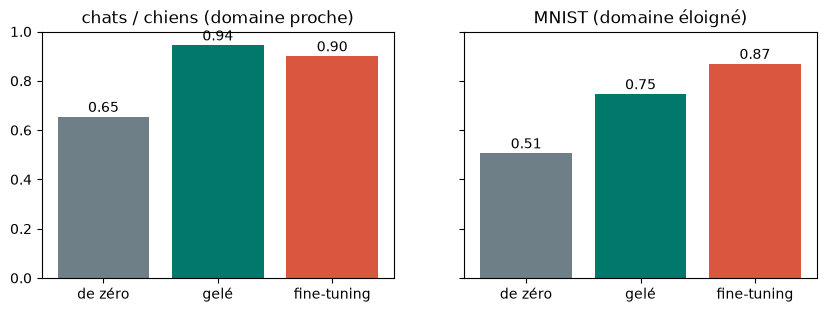

In [9]:
t0 = time.time()
res_mnist = comparer("mnist", mnist, 10)
print("temps : %.0f s" % (time.time() - t0))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for a, (nom, r) in zip(ax, [("chats / chiens (domaine proche)", res_chats), ("MNIST (domaine éloigné)", res_mnist)]):
    a.bar(list(r), list(r.values()), color=["#6E7F88", "#00796B", "#D9563F"])
    a.set_title(nom); a.set_ylim(0, 1)
    for i, v in enumerate(r.values()):
        a.text(i, v + 0.02, "%.2f" % v, ha="center")
plt.show()

**Question 4.1** — Comparez les trois stratégies sur les deux domaines. Quelle stratégie gagne
sur chats / chiens, laquelle sur MNIST ? Qu'est-ce que cela vous dit sur la *distance entre le
domaine source et le domaine cible* ?

> *Réponse :*
>
> | (250 images d'entraînement) | de zéro | caractéristiques gelées | fine-tuning complet |
> |---|---|---|---|
> | chats / chiens (domaine **proche**) | 0,642 | **0,944** | 0,900 |
> | MNIST (domaine **éloigné**) | 0,506 | 0,746 | **0,869** |
>
> * **Le transfert gagne toujours très largement sur l'entraînement de zéro** (+30 points sur chats / chiens, +24 à +36 points sur MNIST). Avec 250 images, un CNN de zéro ne peut pas apprendre de bonnes caractéristiques visuelles.
> * **Sur chats / chiens, les caractéristiques gelées gagnent** (0,944 contre 0,900). ImageNet contient 118 races de chiens et 5 classes de chats : les caractéristiques de `layer4` séparent *déjà* presque linéairement les deux classes. Il suffit d'apprendre la tête (1 026 paramètres). Le fine-tuning complet ajuste 11 M de paramètres avec 250 images. Il ajoute du bruit, risque le sur-apprentissage et déforme des caractéristiques qui étaient déjà bonnes (la partie 5 montre que la rétention baisse même avec `lr = 1e-4`).
> * **Sur MNIST, le fine-tuning gagne nettement** (0,869 contre 0,746, soit +12 points). Des traits blancs sur fond noir, agrandis de 28 à 112 pixels, ne ressemblent à aucune photo d'ImageNet. Les caractéristiques de haut niveau (textures, parties d'objets) sont mal adaptées et une tête linéaire ne suffit pas. Il faut **modifier les couches profondes**.
>
> **Conclusion sur la distance entre domaines :** plus le domaine cible est **proche** du domaine source, plus on peut geler de couches, et le gel est alors à la fois moins coûteux et plus sûr. Plus le domaine est **éloigné**, plus il faut ré-entraîner le backbone, surtout ses dernières couches, qui sont les plus spécifiques à la source. Le choix dépend aussi de la quantité de données : plus il y en a, plus le fine-tuning devient intéressant (voir la partie 11, où le fine-tuning sur 1 000 images atteint 0,948). Ces chiffres viennent d'une seule graine : les écarts de moins de 2 à 3 points restent à confirmer.

---
# Partie 5 — L'oubli catastrophique

Un fine-tuning avec un learning rate trop élevé **efface** ce que le modèle avait appris. On le
mesure de deux façons :

* la **précision** sur la tâche cible (validation) ;
* la **connaissance ImageNet conservée** : on rebranche l'*ancienne* tête à 1000 classes sur le
  backbone modifié et on regarde quelle part des images de chats (resp. de chiens) est encore rangée
  dans une classe de chat (resp. de chien) d'ImageNet.


In [10]:
tete_imagenet = torchvision.models.resnet18(
    weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1).fc
CLASSES = {0: range(281, 286), 1: range(151, 269)}     # chats : 281-285 ; chiens : 151-268


def caracteristiques(m, x):
    """Moyenne globale de la sortie de layer4 (ce que reçoit la tête)."""
    x = m.maxpool(m.relu(m.bn1(m.conv1(x))))
    x = m.layer4(m.layer3(m.layer2(m.layer1(x))))
    return x.mean((2, 3))


@torch.no_grad()
def retention(m, X, y):
    """Part des images que l'ancienne tête ImageNet range encore dans la bonne famille."""
    m.eval()
    bonnes = 0
    for i in range(0, len(X), 100):
        pred = tete_imagenet(caracteristiques(m, vers_tenseur(X[i:i + 100]))).argmax(1).tolist()
        bonnes += sum(int(p in CLASSES[int(c)]) for p, c in zip(pred, y[i:i + 100]))
    return bonnes / len(X)


ref = resnet18()
print("connaissance ImageNet conservée avant tout fine-tuning : %.3f" % retention(ref, chats[2], chats[3]))

connaissance ImageNet conservée avant tout fine-tuning : 0.692


In [11]:
resultats_oubli = {}
for lr in (1e-4, 1e-2):
    m = resnet18()
    # fine-tuning complet, 5 époques, 250 images ; après chaque époque on mesure la précision
    # ET la part de connaissance ImageNet encore présente dans le backbone
    h = entrainer(m, chats[0][:250], chats[1][:250], chats[2], chats[3], 5,
                  [dict(params=list(m.parameters()), lr=lr)],
                  apres_epoque=lambda mm: dict(retention=retention(mm, chats[2], chats[3])))
    resultats_oubli[lr] = h
    print("lr %g : précision %s | rétention %s" % (lr, [round(e["acc"], 2) for e in h],
                                                  [round(e["retention"], 2) for e in h]))

lr 0.0001 : précision [0.73, 0.92, 0.91, 0.91, 0.9] | rétention [0.61, 0.47, 0.4, 0.38, 0.38]
lr 0.01 : précision [0.5, 0.5, 0.5, 0.49, 0.5] | rétention [0.0, 0.0, 0.0, 0.0, 0.0]


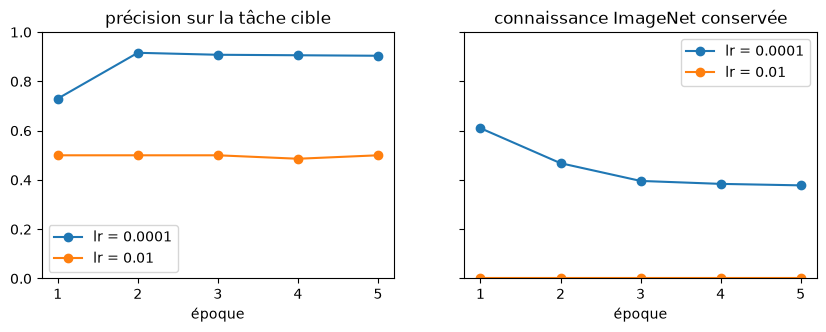

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for lr, h in resultats_oubli.items():
    ax[0].plot(range(1, 6), [e["acc"] for e in h], marker="o", label="lr = %g" % lr)
    ax[1].plot(range(1, 6), [e["retention"] for e in h], marker="o", label="lr = %g" % lr)
ax[0].set_title("précision sur la tâche cible"); ax[1].set_title("connaissance ImageNet conservée")
for a in ax:
    a.set_xlabel("époque"); a.legend(); a.set_ylim(0, 1)
plt.show()

**Question 5.1** — Que se passe-t-il avec `lr = 1e-2` sur la précision ET sur la rétention ?
Pourquoi un learning rate qui est *raisonnable* pour entraîner de zéro est-il *catastrophique* en
fine-tuning ?

> *Réponse :*
>
> Avec **`lr = 1e-2`**, la précision reste bloquée à **0,50 à toutes les époques**. Sur un problème binaire équilibré, c'est le hasard : le réseau prédit toujours la même classe. La **rétention tombe de 0,69 à 0,00 dès la première époque** : toute la connaissance d'ImageNet est effacée. Le réseau a perdu ses anciennes caractéristiques sans en apprendre de nouvelles. C'est l'**oubli catastrophique**.
>
> Avec **`lr = 1e-4`**, la précision monte à 0,91–0,92 dès la deuxième époque. La rétention baisse elle aussi, mais *progressivement* (0,69 → 0,38). Même un fine-tuning « sage » spécialise le backbone sur la nouvelle tâche, et l'ancienne tête à 1 000 classes devient de moins en moins compatible avec lui. Ce compromis entre tâche nouvelle et tâche ancienne existe toujours ; c'est son amplitude que le learning rate contrôle.
>
> **Pourquoi `1e-2` convient de zéro mais pas en fine-tuning :**
> * **De zéro**, les poids sont aléatoires : il n'y a rien à préserver. Un grand pas aide à explorer et à quitter vite la zone de départ.
> * **En fine-tuning**, les poids pré-entraînés sont déjà dans une très bonne région de l'espace des paramètres, et on veut seulement s'en **écarter un peu**. Or au début, la tête est aléatoire : la perte et les gradients sont grands, et ces gradients remontent dans tout le réseau. Avec Adam, chaque poids bouge d'environ `lr` par pas, quelle que soit la taille du gradient. À `1e-2`, cet ordre de grandeur est comparable à la valeur des poids de convolution eux-mêmes (quelques centièmes). En quelques dizaines de pas, les filtres appris sur 1,28 million d'images sont **écrasés** par du bruit, et les statistiques de BN deviennent incohérentes avec les nouveaux poids.
>
> **Parades :** un learning rate 10 à 100 fois plus petit qu'en entraînement de zéro, un *warm-up*, l'entraînement de la tête d'abord (le backbone ne reçoit alors plus de gradients aléatoires), des learning rates discriminatifs ou le dégel progressif (partie 8).

---
# Partie 6 — La normalisation ImageNet oubliée

On extrait les caractéristiques de `layer4` avec différents prétraitements, puis on entraîne une
régression logistique dessus (backbone gelé : seul le prétraitement change).


In [13]:
@torch.no_grad()
def extraire(m, X, norm="imagenet"):
    m.eval()
    out = []
    for i in range(0, len(X), 100):
        out.append(caracteristiques(m, vers_tenseur(X[i:i + 100], norm)))
    return torch.cat(out).numpy()


def sonde(ftr, ytr, fva, yva):
    sc = StandardScaler().fit(ftr)
    clf = LogisticRegression(max_iter=3000).fit(sc.transform(ftr), ytr)
    return clf.score(sc.transform(fva), yva)


ref = resnet18()
acc_norm = {}
for norm in ("imagenet", "zero_un", "brut", "bgr"):
    ftr = extraire(ref, chats[0][:500], norm)      # 500 images d'entraînement
    fva = extraire(ref, chats[2], norm)            # 500 images de validation
    acc_norm[norm] = sonde(ftr, chats[1][:500], fva, chats[3])
print({k: round(v, 3) for k, v in acc_norm.items()})

{'imagenet': 0.938, 'zero_un': 0.882, 'brut': 0.608, 'bgr': 0.95}


**Question 6.1** — Aucune de ces variantes ne produit d'erreur ni d'avertissement. Quelle est la
chute de performance la plus forte ? Proposez deux moyens de vous protéger de cette erreur dans un
projet réel.

> *Réponse :*
>
> | prétraitement | `imagenet` (correct) | `zero_un` (/255 seulement) | `brut` (0..255) | `bgr` (canaux inversés) |
> |---|---|---|---|---|
> | précision de la sonde | 0,938 | 0,882 (−5,6 pts) | **0,608 (−33 pts)** | 0,950 (+1,2 pt) |
>
> **La chute la plus forte vient des valeurs brutes 0..255** : 0,608, à peine mieux que le hasard (0,5). Les entrées sont environ 250 fois trop grandes. Les activations explosent, les BN figées (statistiques d'ImageNet) normalisent n'importe comment et les ReLU saturent : les caractéristiques de `layer4` ne portent presque plus d'information sur l'image. Avec `zero_un`, l'échelle est seulement décalée (moyenne d'environ 0,45 au lieu de 0, écart-type 4 fois trop petit). La perte est modérée (−5,6 points), mais **invisible** sans une mesure de référence.
>
> L'inversion **BGR** ne coûte rien ici (+1,2 point, dans le bruit : sur 500 images, l'écart-type d'une précision de 0,94 est d'environ $\sqrt{0{,}94 \times 0{,}06 / 500} \approx 1{,}1$ point). Distinguer un chat d'un chien repose sur les formes, pas sur la couleur exacte, et la sonde ré-apprend la séparation. Sur une tâche où la couleur compte (fruits mûrs, peintures), cette erreur coûterait bien plus.
>
> **Se protéger de cette erreur dans un projet réel :**
> 1. **Mettre le prétraitement dans le modèle.** On ajoute la normalisation comme première couche (un `nn.Module` qui fait `(x/255 − μ)/σ`), ou on utilise `weights.transforms()` fourni par torchvision. Le prétraitement est alors sauvegardé et déployé **avec** les poids, et on ne peut plus l'oublier ni l'appliquer deux fois.
> 2. **Des vérifications automatiques.** Des `assert` sur les statistiques d'entrée avant la passe avant (moyenne ≈ 0, écart-type ≈ 1, `dtype` float, ordre des canaux), et un **test de non-régression** : une image de référence (par exemple un chat) doit donner la classe ImageNet attendue avec le modèle pré-entraîné, comme la mesure de *rétention* de la partie 5. On complète par une métrique de référence suivie à chaque entraînement, pour qu'une chute silencieuse soit repérée.

---
# Partie 7 — La batch norm en fine-tuning

On fine-tune tout le réseau (250 images, `lr = 1e-4`, 5 époques) en variant la **taille du lot** (32
ou 4) et le **mode de la BN** : normale (`train`, statistiques du lot) ou figée (`eval`, statistiques
d'ImageNet conservées).


In [14]:
resultats_bn = {}
for nom, bs, mode in [("lot 32, BN train", 32, "train"), ("lot 32, BN figée", 32, "eval"),
                      ("lot 4, BN train", 4, "train"), ("lot 4, BN figée", 4, "eval")]:
    m = resnet18()
    h = entrainer(m, chats[0][:250], chats[1][:250], chats[2], chats[3], 5,
                  [dict(params=list(m.parameters()), lr=1e-4)], bs=bs, bn=mode)
    resultats_bn[nom] = h[-1]["acc"]
    print("%-18s précision finale %.3f" % (nom, resultats_bn[nom]))

lot 32, BN train   précision finale 0.912
lot 32, BN figée   précision finale 0.942
lot 4, BN train    précision finale 0.914
lot 4, BN figée    précision finale 0.920


**Question 7.1** — Que constatez-vous ? Rappelez pourquoi les statistiques d'un lot de 4 images
sont mauvaises, et dans quel cas la BN figée est le bon choix.

> *Réponse :*
>
> | fine-tuning, 250 images, `lr = 1e-4`, 5 époques | BN `train` | BN figée (`eval`) |
> |---|---|---|
> | lot de 32 | 0,912 | **0,942** |
> | lot de 4 | 0,914 | 0,920 |
>
> **Constat :** la **BN figée donne le meilleur résultat dans les deux cas**, avec +3 points pour le lot de 32 (0,942, la meilleure configuration). La dégradation attendue « lot 4 + BN train » n'apparaît pas nettement ici : 0,914 contre 0,912, un écart dans le bruit d'une seule graine. Les lots de 4 ont aussi un autre effet : à learning rate égal, ils font 8 fois plus de pas, plus bruités. Cela explique en partie pourquoi « lot 4, BN figée » (0,920) reste en dessous de « lot 32, BN figée ».
>
> **Pourquoi les statistiques d'un lot de 4 sont mauvaises :** la BN estime une moyenne et une variance par canal sur les images du lot. Les pixels d'une même image sont très corrélés, donc l'information effective vient surtout du **nombre d'images** : 4 images ne donnent qu'une estimation très bruitée. En entraînement, chaque image est alors normalisée différemment selon les 3 autres images du lot, ce qui ajoute un bruit fort. Les poids apprennent avec cette normalisation bruitée, mais en évaluation on utilise les moyennes glissantes : le décalage entre entraînement et test grandit. Enfin, les statistiques glissantes d'ImageNet, estimées sur 1,28 million d'images, sont **remplacées** progressivement (momentum 0,1) par des estimations faites sur quelques lots de 4 images.
>
> **La BN figée est le bon choix quand :** les lots sont petits (grandes images, détection, segmentation, mémoire GPU limitée), il y a **peu de données** cibles et le domaine est **proche** de la source, si bien que les statistiques d'ImageNet restent valables (chats / chiens). Si le domaine est très éloigné (MNIST, imagerie médicale), les statistiques d'ImageNet ne correspondent plus. Il vaut mieux alors laisser la BN s'adapter avec des lots assez grands, la recalibrer (comme `recalibrer_bn`), ou utiliser une normalisation indépendante du lot (GroupNorm, LayerNorm).

---
# Partie 8 — Learning rates discriminatifs et dégel progressif

Sur le domaine **éloigné** (MNIST, 250 images, 8 époques), on compare :

* un learning rate **unique** `1e-3` pour tous les paramètres ;
* des learning rates **discriminatifs** : plus petits pour les premières couches (génériques), plus
  grands pour les dernières : `1e-5` (stem + layer1), `1e-4` (layer2-3), `3e-4` (layer4), `1e-3` (tête) ;
* le **dégel progressif** : tête seule aux époques 1-2, puis `layer4` (3-4), puis `layer3` (5-6), puis tout
  (7-8).


In [15]:
def groupes_discriminatifs(m, lrs):
    """Quatre groupes de paramètres, un learning rate par groupe."""
    stem = list(m.conv1.parameters()) + list(m.bn1.parameters())
    return [dict(params=stem + list(m.layer1.parameters()), lr=lrs[0]),
            dict(params=list(m.layer2.parameters()) + list(m.layer3.parameters()), lr=lrs[1]),
            dict(params=list(m.layer4.parameters()), lr=lrs[2]),
            dict(params=list(m.fc.parameters()), lr=lrs[3]),
            ]


xtr, ytr, xva, yva = mnist
res8 = {}
m = resnet18(True, 10)
h = entrainer(m, xtr[:250], ytr[:250], xva, yva, 8, [dict(params=list(m.parameters()), lr=1e-3)])
res8["LR unique 1e-3"] = h[-1]["acc"]
m = resnet18(True, 10)
h = entrainer(m, xtr[:250], ytr[:250], xva, yva, 8, groupes_discriminatifs(m, [1e-5, 1e-4, 3e-4, 1e-3]))
res8["LR discriminatifs"] = h[-1]["acc"]
print({k: round(v, 3) for k, v in res8.items()})

{'LR unique 1e-3': 0.879, 'LR discriminatifs': 0.895}


In [16]:
def faire_degel(m):
    """Retourne le rappel `avant_epoque` du dégel progressif."""
    ordre = [list(m.fc.parameters()), list(m.layer4.parameters()), list(m.layer3.parameters()),
             list(m.layer2.parameters()) + list(m.layer1.parameters())
             + list(m.conv1.parameters()) + list(m.bn1.parameters())]
    debut = {0: 0, 2: 1, 4: 2, 6: 3}                    # époque -> groupe à dégeler

    def avant(ep, mm, optim):
        if ep in debut:
            k = debut[ep]
            for p in ordre[k]:                      # on dégèle ce groupe...
                p.requires_grad = True
            # ... et on le confie à l'optimiseur (lr 1e-3 pour la tête, 1e-4 ensuite)
            optim.add_param_group(dict(params=ordre[k], lr=1e-3 if k == 0 else 1e-4))
            print("époque %d : groupe %d dégelé, %d paramètres entraînables" % (ep + 1, k, n_entrainables(mm)))
    return avant


m = resnet18(True, 10)
for p in m.parameters():
    p.requires_grad = False
factice = nn.Parameter(torch.zeros(1))                  # l'optimiseur exige au moins un groupe
h = entrainer(m, xtr[:250], ytr[:250], xva, yva, 8, [dict(params=[factice], lr=0.0)],
              avant_epoque=faire_degel(m))
res8["dégel progressif"] = h[-1]["acc"]
print({k: round(v, 3) for k, v in res8.items()})

époque 1 : groupe 0 dégelé, 5130 paramètres entraînables
époque 3 : groupe 1 dégelé, 8398858 paramètres entraînables
époque 5 : groupe 2 dégelé, 10498570 paramètres entraînables
époque 7 : groupe 3 dégelé, 11181642 paramètres entraînables
{'LR unique 1e-3': 0.879, 'LR discriminatifs': 0.895, 'dégel progressif': 0.856}


**Question 8.1** — Classez les trois stratégies. L'écart est-il grand ? Les mesures portent sur une
seule graine et 1 000 images de validation : que pouvez-vous affirmer, et que ne pouvez-vous pas
affirmer ?

> *Réponse :*
>
> **Classement (MNIST, 250 images, 8 époques) :** LR discriminatifs **0,895** > LR unique `1e-3` **0,879** > dégel progressif **0,856**.
>
> **L'écart est faible** : 1,6 point entre les deux premiers, 3,9 points entre le premier et le dernier. À comparer avec les écarts de la partie 4 : 0,506 de zéro et 0,746 en gelé.
>
> **Ce qu'on peut affirmer :**
> * Les trois stratégies, qui **adaptent toutes le backbone**, donnent 0,86–0,90 sur MNIST. C'est bien mieux que les caractéristiques gelées (0,746) ou l'entraînement de zéro (0,506) : sur un domaine éloigné, ce qui compte avant tout est d'adapter les couches profondes.
> * Un learning rate unique de `1e-3`, catastrophique sur chats / chiens à `1e-2`, n'empêche pas ici d'atteindre 0,88. Sur un domaine éloigné, on perd moins à « oublier » ImageNet.
>
> **Ce qu'on ne peut pas affirmer :**
> * Que les LR discriminatifs sont *meilleurs* en général. Sur 1 000 images de validation, l'erreur-type d'une précision de 0,88 vaut $\sqrt{0{,}88 \times 0{,}12 / 1000} \approx 1$ point, soit un intervalle de confiance à 95 % d'environ ±2 points. À cela s'ajoute la **variance due à la graine** (initialisation de la tête, ordre des lots), souvent de 1 à 3 points en fine-tuning sur 250 images. Un écart de 1,6 point sur **une seule graine** n'est pas significatif.
> * Que le dégel progressif est moins bon *par nature*. Avec seulement 8 époques, le réseau entier n'est entraîné que pendant 2 époques, et `layer1`–`layer2` à `1e-4`. Le protocole le désavantage, et avec plus d'époques le classement pourrait changer.
>
> **Pour conclure vraiment**, il faudrait répéter chaque stratégie avec 5 à 10 graines, présenter la moyenne ± l'écart-type, faire un test apparié sur les mêmes images, et vérifier que la conclusion tient pour d'autres tailles de données et d'autres budgets d'époques. Comme le dit le bilan : un effet à **mesurer**, pas à supposer.

---
# Partie 9 — LoRA en miniature

Pour un très grand modèle, même le fine-tuning de `layer4` est trop coûteux. **LoRA** (*low-rank
adaptation*) gèle la matrice `W` (`d × k`) et n'apprend qu'une correction de **rang faible** :

$$ y = W x + \frac{\alpha}{r}\, B A x, \qquad A \in \mathbb{R}^{r\times k},\ B \in \mathbb{R}^{d\times r} $$

On initialise `B = 0` : au départ, le modèle adapté est **identique** au modèle source.


In [17]:
class LoRALineaire(nn.Module):
    """Couche linéaire gelée W, plus une correction de rang r : y = W x + (alpha/r) B A x."""

    def __init__(self, base, r=8, alpha=16):
        super().__init__()
        self.base = base
        for p in self.base.parameters():
            p.requires_grad = False
        self.A = nn.Parameter(0.01 * torch.randn(r, base.in_features))   # r x k, petit aléa
        self.B = nn.Parameter(torch.zeros(base.out_features, r))         # d x r, nul au départ
        self.echelle = alpha / r

    def forward(self, x):
        # W x (gelé) + (alpha / r) * B (A x) : on ne forme jamais la matrice d x k de BA
        return self.base(x) + self.echelle * (x @ self.A.t()) @ self.B.t()


W = nn.Linear(512, 512)
lora = LoRALineaire(W, r=8)
x = torch.randn(4, 512)
print("sortie identique au départ :", torch.allclose(lora(x), W(x)))
entrainables = sum(p.numel() for p in lora.parameters() if p.requires_grad)
print("paramètres : W = %d | LoRA entraînables = %d (%.1f %%)"
      % (W.weight.numel(), entrainables, 100 * entrainables / W.weight.numel()))

sortie identique au départ : True
paramètres : W = 262144 | LoRA entraînables = 8192 (3.1 %)


In [18]:
# Après quelques pas, seule la correction bouge ; W reste inchangée.
W0 = W.weight.detach().clone()
cible = torch.randn(4, 512)
opt = torch.optim.Adam([p for p in lora.parameters() if p.requires_grad], lr=1e-2)
for _ in range(50):
    perte = F.mse_loss(lora(x), cible)
    opt.zero_grad(); perte.backward(); opt.step()
print("perte finale : %.3f | W modifiée : %s | B nulle : %s"
      % (perte.item(), not torch.equal(W.weight, W0), bool((lora.B == 0).all())))

perte finale : 0.002 | W modifiée : False | B nulle : False


**Question 9.1** — Pour un `W` de taille `4096 × 4096` et un rang `r = 8`, combien de paramètres
LoRA entraîne-t-elle, et quelle fraction de `W` cela représente-t-il ? Pourquoi initialiser `B` à
zéro plutôt qu'`A` ?

> *Réponse :*
>
> **Nombre de paramètres :** $A \in \mathbb{R}^{r \times k}$ et $B \in \mathbb{R}^{d \times r}$, soit $r(d + k) = 8 \times (4096 + 4096) = 65\,536$ paramètres entraînables, contre $d \cdot k = 4096^2 = 16\,777\,216$ pour $W$. Cela fait **0,39 %** de $W$ (exactement $2r/d = 1/256$), soit 256 fois moins. *Vérification sur l'exemple du notebook :* $W$ de 512 × 512, $r = 8$, donne $8 \times 1024 = 8\,192$ paramètres, soit 3,1 % ($2r/d = 16/512$), exactement ce qui est affiché. La fraction baisse quand la couche grandit : LoRA est d'autant plus utile que le modèle est grand. On ne garde en mémoire les états de l'optimiseur (moments d'Adam) que pour ces 65 536 paramètres. Après l'entraînement, on peut **fusionner** $W' = W + \frac{\alpha}{r}BA$, sans aucun surcoût à l'inférence.
>
> **Pourquoi initialiser $B$ à zéro ?**
> 1. **Partir exactement du modèle source.** Avec $B = 0$, la correction $\frac{\alpha}{r}BAx$ est nulle et le modèle adapté est identique au modèle pré-entraîné : le notebook l'affiche (« sortie identique au départ : True »). On ne commence pas le fine-tuning en abîmant le modèle avec une perturbation aléatoire, ce qui rejoint la leçon de la partie 5.
> 2. **On ne peut pas mettre les deux à zéro.** Les gradients sont $\partial L/\partial B \propto g\,(Ax)^\top$ et $\partial L/\partial A \propto B^\top g\,x^\top$. Si $A = B = 0$, les deux gradients sont nuls et rien n'apprend jamais. Il faut donc **un facteur nul (pour l'identité) et l'autre aléatoire (pour que le gradient circule)**.
> 3. **Pourquoi $B$ plutôt que $A$ ?** Avec $A$ aléatoire, $Ax$ est une **projection aléatoire** de l'entrée sur $r$ dimensions. Une telle projection conserve à peu près la géométrie des entrées (lemme de Johnson–Lindenstrauss). Dès le premier pas, $B$ reçoit un gradient $g\,(Ax)^\top$ informatif, et le problème ressemble à une régression linéaire de la correction voulue à partir de ces $r$ projections. C'est le choix de l'article original de LoRA (Hu et al., 2021). La cellule précédente le confirme : après 50 pas, la perte vaut 0,002, $B$ n'est plus nulle et $W$ n'a pas bougé.

---
# Partie 10 — Votre corpus d'œuvres (optionnel)

Si vous disposez d'un corpus d'œuvres rangé en **un dossier par classe** (mouvement, école,
technique), le code ci-dessous le charge et le prépare exactement comme les données précédentes.
Rien n'est exécuté si le dossier n'existe pas.


In [19]:
from PIL import Image

def charger_corpus(dossier, par_classe=60):
    """dossier/classe_a/*.jpg, dossier/classe_b/*.jpg ... -> tableaux uint8 RES x RES, étiquettes."""
    classes = sorted(d for d in os.listdir(dossier) if os.path.isdir(os.path.join(dossier, d)))
    X, y = [], []
    for k, c in enumerate(classes):
        for f in sorted(os.listdir(os.path.join(dossier, c)))[:par_classe]:
            im = Image.open(os.path.join(dossier, c, f)).convert("RGB")
            s = min(im.size); l, t = (im.width - s) // 2, (im.height - s) // 2
            X.append(np.asarray(im.crop((l, t, l + s, t + s)).resize((RES, RES), Image.BILINEAR))); y.append(k)
    return np.stack(X), np.array(y), classes

CORPUS = "mon_corpus_oeuvres"
if os.path.isdir(CORPUS):
    X, y, classes = charger_corpus(CORPUS)
    print(len(X), "images,", len(classes), "classes :", classes)
    # À vous : appliquez comparer(...) avec les trois stratégies, puis discutez la distance au domaine ImageNet.
else:
    print("pas de corpus d'œuvres trouvé dans", CORPUS, "- partie ignorée")

pas de corpus d'œuvres trouvé dans mon_corpus_oeuvres - partie ignorée


---
# Partie 11 — Application : le dossier d'images `chats_chiens/`

Les images brutes (JPEG de tailles variées) étaient fournies avec le *train* et le *test* mélangés à la racine du TP. Elles ont été rangées ainsi :

```
chats_chiens/
├── train/
│   ├── chats/    500 images  (cat.*.jpg)
│   └── chiens/   500 images  (dog.*.jpg)
└── test/        168 images  (1.jpg … 168.jpg, **sans étiquette**)
```

Le *train* respecte maintenant la convention « un dossier par classe », ce qui permet de le charger directement avec `charger_corpus` (partie 10). Le *test* n'a pas d'étiquette : on ne peut pas y mesurer une précision, seulement y **appliquer** le modèle. On valide donc sur les 500 images de validation du fichier `.npz` (vérifié : aucune de ces images ne figure dans le dossier `train/`).


In [20]:
DOSSIER_CC = os.path.join(DOSSIER, "chats_chiens")
Xd, yd, classes_d = charger_corpus(os.path.join(DOSSIER_CC, "train"), par_classe=500)
print(len(Xd), "images d'entraînement | classes :", classes_d, "| effectifs :", np.bincount(yd))

# Même convention que le .npz : 0 = chat, 1 = chien (ordre alphabétique des dossiers)
NOMS = {0: "chat", 1: "chien"}

# Fine-tuning complet (la stratégie gagnante sur ce domaine proche, partie 4) sur les 1 000 images
t0 = time.time()
m_final = resnet18(True, 2)
h_final = entrainer(m_final, Xd, yd, chats[2], chats[3], 3,
                    [dict(params=list(m_final.parameters()), lr=1e-4)], eval_chaque=True)
print("précision de validation par époque :", [round(e["acc"], 3) for e in h_final],
      "| temps : %.0f s" % (time.time() - t0))


1000 images d'entraînement | classes : ['chats', 'chiens'] | effectifs : [500 500]
précision de validation par époque : [0.926, 0.948, 0.91] | temps : 138 s


168 images de test | prédites chat : 99 | chien : 69
confiance moyenne : 0.966 | images douteuses (confiance < 0,7) : 6
prédictions écrites dans .\chats_chiens\predictions_test.csv


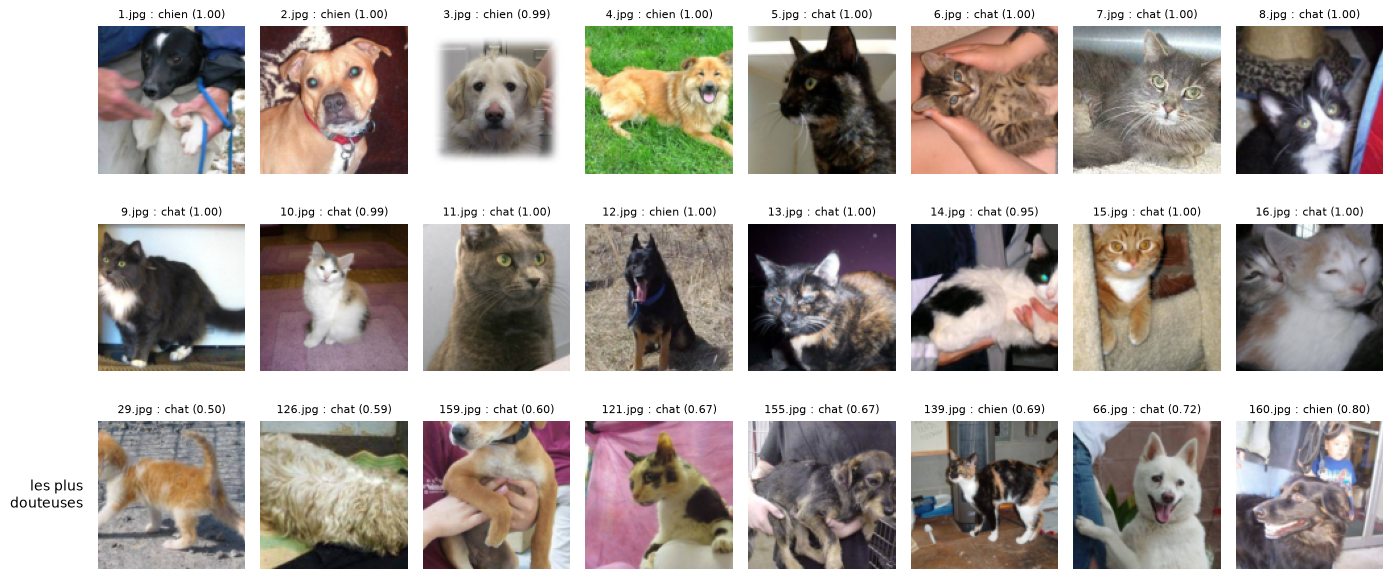

In [21]:
def charger_images(dossier):
    """Toutes les images d'un dossier (sans sous-dossier de classe), recadrées au centre en RES x RES."""
    fichiers = sorted((f for f in os.listdir(dossier) if f.lower().endswith((".jpg", ".jpeg", ".png"))),
                      key=lambda f: int(os.path.splitext(f)[0]) if os.path.splitext(f)[0].isdigit() else f)
    X = []
    for f in fichiers:
        im = Image.open(os.path.join(dossier, f)).convert("RGB")
        s = min(im.size); l, t = (im.width - s) // 2, (im.height - s) // 2
        X.append(np.asarray(im.crop((l, t, l + s, t + s)).resize((RES, RES), Image.BILINEAR)))
    return np.stack(X), fichiers


@torch.no_grad()
def predire(m, X):
    """Probabilités (softmax) pour chaque image."""
    m.eval()
    return torch.cat([F.softmax(m(vers_tenseur(X[i:i + 100])), 1) for i in range(0, len(X), 100)]).numpy()


Xt, fichiers_t = charger_images(os.path.join(DOSSIER_CC, "test"))
proba = predire(m_final, Xt)
pred = proba.argmax(1)
print(len(Xt), "images de test | prédites chat :", (pred == 0).sum(), "| chien :", (pred == 1).sum())
print("confiance moyenne : %.3f | images douteuses (confiance < 0,7) : %d"
      % (proba.max(1).mean(), (proba.max(1) < 0.7).sum()))

# Sauvegarde des prédictions
with open(os.path.join(DOSSIER_CC, "predictions_test.csv"), "w", encoding="utf-8") as f:
    f.write("fichier,prediction,proba_chien\n")
    for nom_f, p, pr in zip(fichiers_t, pred, proba[:, 1]):
        f.write("%s,%s,%.4f\n" % (nom_f, NOMS[int(p)], pr))
print("prédictions écrites dans", os.path.join(DOSSIER_CC, "predictions_test.csv"))

# Les 16 premières images de test, puis les 8 où le modèle hésite le plus
douteuses = np.argsort(proba.max(1))[:8]
fig, ax = plt.subplots(3, 8, figsize=(14, 6.2))
for a, i in zip(ax.ravel(), list(range(16)) + list(douteuses)):
    a.imshow(Xt[i]); a.axis("off")
    a.set_title("%s : %s (%.2f)" % (fichiers_t[i], NOMS[int(pred[i])], proba[i].max()), fontsize=8)
ax[2, 0].text(-0.1, 0.5, "les plus\ndouteuses", transform=ax[2, 0].transAxes, ha="right", va="center")
plt.tight_layout(); plt.show()


**Commentaire des résultats de la partie 11.**

* **Entraînement.** En fine-tuning complet sur les **1 000 images** du dossier `train/` (contre 250 dans la partie 4), la précision de validation atteint **0,948** à la 2ᵉ époque, au-dessus du meilleur résultat obtenu avec 250 images (0,944 en gelé). Avec plus de données, le fine-tuning complet devient compétitif sur le domaine proche. Elle redescend à 0,910 à la 3ᵉ époque : avec 11 M de paramètres et 1 000 images, le modèle commence à sur-apprendre, ou fluctue. En pratique, on garderait **le meilleur modèle sur la validation** (*early stopping*) au lieu du dernier.
* **Test.** Sur les 168 images de `test/` (sans étiquette), le modèle prédit 99 chats et 69 chiens, avec une confiance moyenne de 0,966. Seules 6 images ont une confiance inférieure à 0,7. On ne connaît pas la vraie répartition, donc on ne peut **pas** calculer de précision sur ce dossier. L'inspection visuelle montre que **les 16 premières images sont toutes correctement classées**.
* **Cas douteux.** Les erreurs visibles se concentrent sur les images de faible confiance : des **chiots tenus dans les bras** (159.jpg, 155.jpg classés « chat » à 0,60–0,67), un chat tricolore dans une pièce encombrée (139.jpg classé « chien » à 0,69) et un chien blanc au poil long (66.jpg). Ce sont des images où l'animal est petit, partiellement masqué par des mains ou coupé par le **recadrage central** en 112 × 112. La confiance du modèle est donc un **bon signal** pour repérer les images à vérifier à la main. Pour aller plus loin : une résolution plus élevée (224, celle d'ImageNet), de l'augmentation de données (recadrages aléatoires, symétries) et le moyennage de plusieurs recadrages au test (*test-time augmentation*).
* Les prédictions sont enregistrées dans `chats_chiens/predictions_test.csv` (fichier, classe prédite, probabilité « chien »).

---
# Bilan

| Notion | Ce que vous avez vérifié |
|---|---|
| Prétraitement | il fait partie du modèle : l'oublier fait chuter la précision **sans erreur** |
| Gel | `requires_grad = False` ne gèle pas les **statistiques** de la BN : il faut `eval()` |
| Stratégie | dépend de la taille des données et de la **distance** au domaine source |
| Oubli catastrophique | un learning rate trop élevé efface le pré-entraînement : précision et rétention chutent |
| BN en fine-tuning | petits lots : statistiques bruitées, BN figée plus sûre |
| LR discriminatifs, dégel | utiles surtout quand le domaine est éloigné ; effet à mesurer, pas à supposer |
| LoRA | `r·(d + k)` paramètres au lieu de `d·k`, modèle identique au départ |

**Au chapitre 5**, on quitte les images : les réseaux récurrents traitent des séquences. Le
transfert reviendra avec les modèles de langue pré-entraînés.


---
# Synthèse des résultats obtenus

| Partie | Mesure | Résultat |
|---|---|---|
| 2 | part des paramètres dans `layer4` | 75,1 % (8,4 M sur 11,2 M) |
| 3 | paramètres entraînables après gel | 1 026 sur 11 177 538 ; stats BN modifiées malgré le gel |
| 4 | chats / chiens : zéro / gelé / fine-tuning | 0,642 / **0,944** / 0,900 |
| 4 | MNIST : zéro / gelé / fine-tuning | 0,506 / 0,746 / **0,869** |
| 5 | `lr = 1e-4` : précision, rétention ImageNet | 0,90, rétention 0,69 → 0,38 |
| 5 | `lr = 1e-2` : précision, rétention ImageNet | **0,50 (hasard), rétention 0,00** |
| 6 | sonde : imagenet / zero_un / brut / bgr | 0,938 / 0,882 / **0,608** / 0,950 |
| 7 | BN train / figée (lot 32) ; (lot 4) | 0,912 / **0,942** ; 0,914 / 0,920 |
| 8 | MNIST : LR unique / discriminatifs / dégel | 0,879 / **0,895** / 0,856 (écarts dans le bruit) |
| 9 | LoRA r = 8 sur 512 × 512 ; sur 4096 × 4096 | 3,1 % ; 0,39 % des paramètres |
| 11 | fine-tuning sur le dossier `train/` (1 000 images) | **0,948** en validation ; 168 images de test prédites |

**À retenir.** Avec peu de données, le transfert d'apprentissage bat toujours l'entraînement de zéro. Le choix entre geler et fine-tuner dépend de la **distance au domaine source** : on gèle pour un domaine proche, on adapte les couches profondes pour un domaine éloigné. Les erreurs les plus dangereuses sont **silencieuses** : un prétraitement oublié, une BN qui bouge malgré le gel, un learning rate qui efface le pré-entraînement. On ne les détecte qu'en **mesurant** (précision de référence, rétention, statistiques d'entrée). Enfin, des écarts de 1 à 2 points sur une seule graine ne permettent pas de conclure.